In [1]:
import os
import pickle
from scripts.utils import path_to_save
import matplotlib.pyplot as plt

In [2]:
with open(os.path.join(path_to_save, 'endpoint_prediction.pkl'), 'rb') as f:
    results = pickle.load(f)

real_errors = results['real_errors']
null_errors = results['null_errors']
reveal_percentages = results['settings']['reveal_percentages']
conditions = results['settings']['conditions']
fractions = [16.6,50,100]

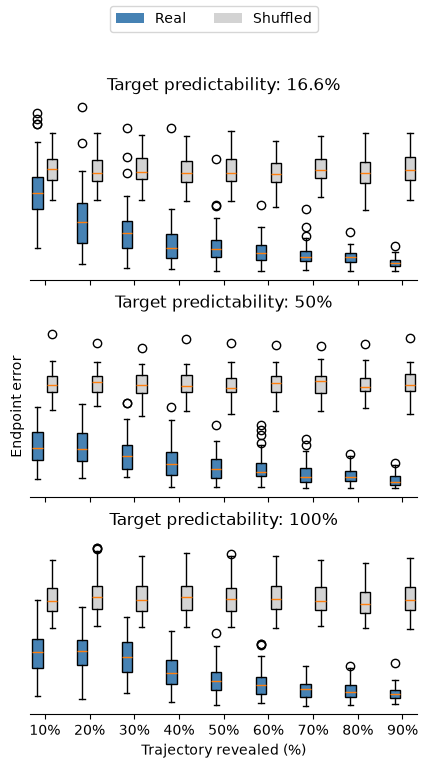

In [4]:
# Plot predicted endpoint errors across different percentages of trajectory revealed
fig, axes = plt.subplots(len(conditions),1,figsize=(5,8),sharex=True,sharey=True)

for n, (ax, condition) in enumerate(zip(axes, conditions)):

    data, positions = [],[]

    for i, percentage in enumerate(reveal_percentages):

        real = real_errors[condition][percentage]
        null = null_errors[condition][percentage].mean(axis=0)
        data.extend([real, null])
        positions.extend([i * 3 + 1, i * 3 + 2])

    bp = ax.boxplot(data, positions=positions, widths=0.7, patch_artist=True)

    for i, box in enumerate(bp['boxes']):
        box.set_facecolor('steelblue' if i % 2 == 0 else 'lightgray')

    ax.set_xticks([i * 3 + 1.5 for i in range(len(reveal_percentages))])
    ax.set_xticklabels([f'{p}%' for p in reveal_percentages])
    ax.set_yticks([])
    ax.set_title(f'Target predictability: {fractions[n]}%')
    if n == 1: ax.set_ylabel('Endpoint error')
    if n == 2: ax.set_xlabel('Trajectory revealed (%)')
    ax.spines[['right','left','top']].set_visible(False)

fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, facecolor='steelblue'),
                    plt.Rectangle((0, 0), 1, 1, facecolor='lightgray')],
            labels=['Real', 'Shuffled'], loc='upper center', ncol=2)
plt.savefig(os.path.join(path_to_save,'endpoint_errors.svg'))